# 01 - Exploratory Data Analysis: Diabetes 130-US Hospitals
**Group 06** - Inspection of shape, missing values (`?`), target distribution (`readmitted`), and patient duplicates (`patient_nbr`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if os.path.exists('../data/raw/diabetic_data.csv'):
    df = pd.read_csv('../data/raw/diabetic_data.csv', na_values='?')
else:
    from google.colab import drive
    drive.mount('/content/drive')
    df = pd.read_csv('/content/drive/MyDrive/ESILV_ML/diabetic_data.csv', na_values='?')

print(f'Dataset shape: {df.shape}')
print(f'Unique patients: {df["patient_nbr"].nunique()} / {len(df)} encounters')
df.head()

Mounted at /content/drive
Dataset shape: (101766, 50)
Unique patients: 71518 / 101766 encounters


/tmp/ipykernel_758/73687097.py:12: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/ESILV_ML/diabetic_data.csv', na_values='?')


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [2]:
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
print('Columns with missing values (%):')
print(missing[missing > 0])

Columns with missing values (%):
weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64


readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64


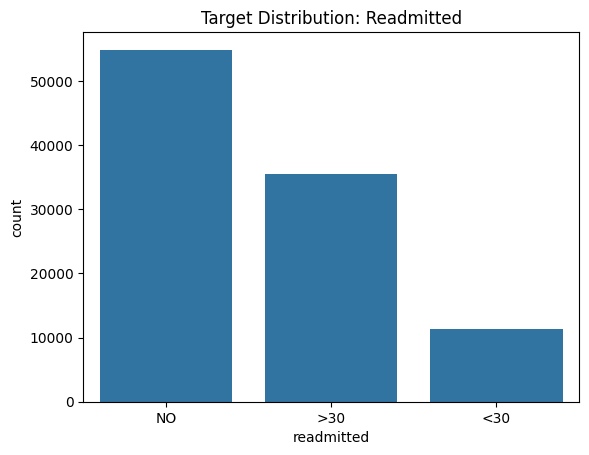

In [3]:
print(df['readmitted'].value_counts(normalize=True) * 100)
sns.countplot(data=df, x='readmitted', order=['NO', '>30', '<30'])
plt.title('Target Distribution: Readmitted')
plt.show()